# Лабораторна робота 2. Етап 2 — аналіз даних (AID, варіант 3)

Окремий ноутбук для **локального запуску** (CPU достатньо): аналіз датасету та підготовка поділу train / val / test.

* кількість класів і зображень, розподіл за класами;
* властивості зображень (розмір, режим, розмір файлів), перевірка на дублікати;
* приклади зображень, схожі між собою класи, середній колір класів;
* стратифікований поділ **70 / 15 / 15** → `split.csv`.

Датасет завантажено заздалегідь через Kaggle CLI у папку `data/`:

```bash
kaggle datasets download jiayuanchengala/aid-scene-classification-datasets -p data --unzip
```

`split.csv` будується тим самим кодом і з тим самим `SEED`, що й в основному ноутбуці (`Lab2_CNN_AID_variant3.ipynb`),
а шляхи в ньому відносні до папки з класами — тому файл можна покласти в `CKPT_DIR` основного ноутбука,
і всі експерименти використають **той самий поділ**.

## 0. Підготовка

In [1]:
import os, hashlib
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from tqdm.auto import tqdm
from sklearn.model_selection import train_test_split

SEED = 42                     # той самий seed, що й в основному ноутбуці -> той самий поділ
IMG_EXT = {'.jpg', '.jpeg', '.png', '.tif', '.tiff', '.bmp'}
OUT_DIR = Path('artifacts')   # сюди зберігаємо split.csv і таблиці
OUT_DIR.mkdir(exist_ok=True)

plt.rcParams['figure.dpi'] = 100

/home/nykfer/Projects/AI/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Датасет

Шукаємо вже завантажений датасет: спочатку локальна папка `data/`, потім `/kaggle/input` (якщо ноутбук запущено на Kaggle).
Якщо нічого не знайдено — завантажуємо через Kaggle CLI.

In [2]:
CANDIDATE_ROOTS = [Path('data'), Path('/kaggle/input/aid-scene-classification-datasets'), Path('/kaggle/input')]

dataset_path = next((p for p in CANDIDATE_ROOTS if p.exists() and any(p.iterdir())), None)
if dataset_path is None:
    dataset_path = Path('data')
    !kaggle datasets download jiayuanchengala/aid-scene-classification-datasets -p {dataset_path} --unzip
print('Датасет:', dataset_path.resolve())

Датасет: /home/nykfer/Projects/AI/data


In [3]:
def find_class_root(root):
    # Папка, всередині якої найбільше підпапок із зображеннями (це і є папки-класи)
    candidates = []
    for dirpath, dirnames, _ in os.walk(root):
        n_classes = sum(any(Path(f).suffix.lower() in IMG_EXT for f in os.listdir(os.path.join(dirpath, d)))
                        for d in dirnames)
        if n_classes >= 2:
            candidates.append((Path(dirpath), n_classes))
    split_words = {'train', 'test', 'val', 'valid', 'validation'}
    best = max(candidates, key=lambda c: (c[1], not (set(p.lower() for p in c[0].parts) & split_words)))
    return best[0]


DATA_DIR = find_class_root(dataset_path)
print('Папка з класами:', DATA_DIR)

Папка з класами: data/AID


## 2. Кількість класів і розподіл зображень

In [4]:
classes = sorted(d.name for d in DATA_DIR.iterdir() if d.is_dir())
class_to_idx = {c: i for i, c in enumerate(classes)}
NUM_CLASSES = len(classes)

# Порядок обходу такий самий, як в основному ноутбуці -> train_test_split дасть ідентичний поділ
records = []
for c in classes:
    for f in sorted((DATA_DIR / c).iterdir()):
        if f.suffix.lower() in IMG_EXT:
            records.append((str(f.relative_to(DATA_DIR)), c, class_to_idx[c]))
df = pd.DataFrame(records, columns=['path', 'class', 'label'])

print(f'Кількість класів: {NUM_CLASSES}')
print(f'Кількість зображень: {len(df)}')
print('Класи:', ', '.join(classes))

Кількість класів: 30
Кількість зображень: 10000
Класи: Airport, BareLand, BaseballField, Beach, Bridge, Center, Church, Commercial, DenseResidential, Desert, Farmland, Forest, Industrial, Meadow, MediumResidential, Mountain, Park, Parking, Playground, Pond, Port, RailwayStation, Resort, River, School, SparseResidential, Square, Stadium, StorageTanks, Viaduct


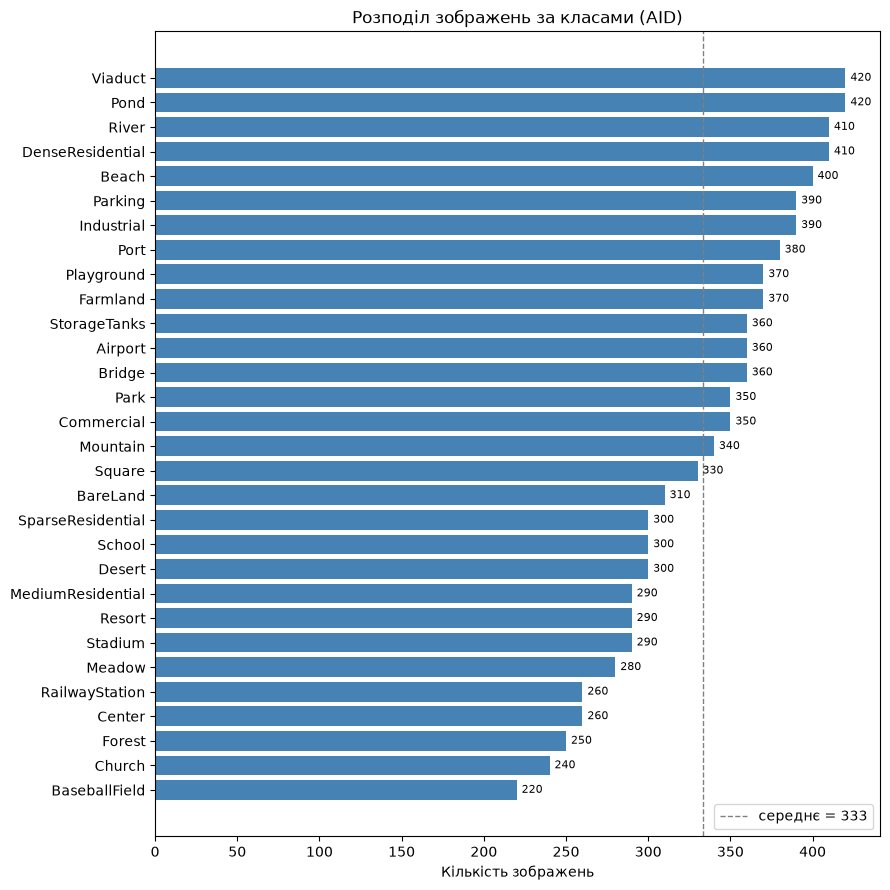

min = 220 (BaseballField), max = 420 (Pond)
співвідношення max/min = 1.91, коефіцієнт варіації = 0.17


In [5]:
counts = df['class'].value_counts().sort_values()

fig, ax = plt.subplots(figsize=(9, 9))
ax.barh(counts.index, counts.values, color='steelblue')
ax.axvline(counts.mean(), color='gray', ls='--', lw=1, label=f'середнє = {counts.mean():.0f}')
for y, v in enumerate(counts.values):
    ax.text(v + 3, y, str(v), va='center', fontsize=8)
ax.set_xlabel('Кількість зображень')
ax.set_title('Розподіл зображень за класами (AID)')
ax.legend(loc='lower right')
plt.tight_layout()
plt.show()

print(f'min = {counts.min()} ({counts.idxmin()}), max = {counts.max()} ({counts.idxmax()})')
print(f'співвідношення max/min = {counts.max() / counts.min():.2f}, '
      f'коефіцієнт варіації = {counts.std() / counts.mean():.2f}')

In [6]:
# Таблиця: частка кожного класу та точність «завжди найчисельніший клас» (нижня межа для моделей)
class_table = (counts.sort_values(ascending=False).rename('count').to_frame()
               .assign(share=lambda t: (t['count'] / t['count'].sum()).round(4)))
print(f'Baseline (завжди {counts.idxmax()}): accuracy = {counts.max() / len(df):.3f}; '
      f'випадкове вгадування: {1 / NUM_CLASSES:.3f}')
class_table.T

Baseline (завжди Pond): accuracy = 0.042; випадкове вгадування: 0.033


class,Pond,Viaduct,DenseResidential,River,Beach,Industrial,Parking,Port,Farmland,Playground,...,SparseResidential,MediumResidential,Resort,Stadium,Meadow,Center,RailwayStation,Forest,Church,BaseballField
count,420.000,420.000,410.000,410.000,400.00,390.000,390.000,380.000,370.000,370.000,...,300.00,290.000,290.000,290.000,280.000,260.000,260.000,250.000,240.000,220.000
share,0.042,0.042,0.041,0.041,0.04,0.039,0.039,0.038,0.037,0.037,...,0.03,0.029,0.029,0.029,0.028,0.026,0.026,0.025,0.024,0.022


**Висновок щодо розподілу** _(перевірити після запуску)_: класи помірно незбалансовані (приблизно 220–420 зображень на клас,
max/min ≈ 1.9). Дисбаланс не критичний, тож зважування класів чи oversampling не обов'язкові, але:
* окрім accuracy рахуємо **macro-F1**, яка однаково враховує малі й великі класи;
* поділ робимо **стратифікованим**, щоб частки класів у train / val / test збігалися.

## 3. Властивості зображень

Читаємо лише заголовки файлів (без декодування пікселів) — це швидко навіть для всіх ~10 000 зображень.
Також рахуємо MD5 файлів, щоб знайти точні дублікати (вони можуть потрапити і в train, і в test — витік даних).

In [7]:
def image_info(rel_path):
    p = DATA_DIR / rel_path
    with Image.open(p) as im:
        w, h = im.size
        mode = im.mode
    data = p.read_bytes()
    return w, h, mode, len(data) / 1024, hashlib.md5(data).hexdigest()


info = [image_info(p) for p in tqdm(df['path'], desc='Читання заголовків')]
df[['width', 'height', 'mode', 'size_kb', 'md5']] = pd.DataFrame(info, index=df.index)

print('Розміри (W×H):', Counter(zip(df.width, df.height)).most_common(5))
print('Режими:', dict(Counter(df['mode'])))
print(f'Розмір файлу: медіана {df.size_kb.median():.0f} КБ, '
      f'min {df.size_kb.min():.0f}, max {df.size_kb.max():.0f} КБ, усього {df.size_kb.sum() / 1024**2:.2f} ГБ')

Читання заголовків: 100%|██████████| 10000/10000 [00:09<00:00, 1088.25it/s]

Розміри (W×H): [((600, 600), 10000)]
Режими: {'RGB': 10000}
Розмір файлу: медіана 249 КБ, min 31, max 808 КБ, усього 2.53 ГБ


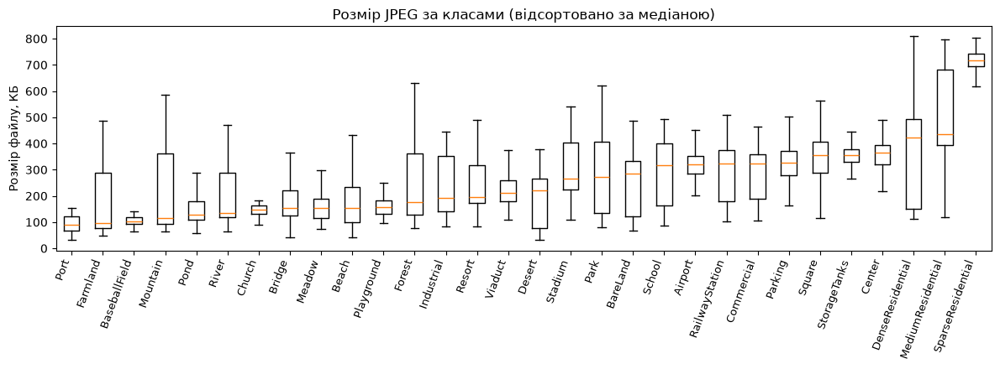

In [8]:
# Розмір JPEG-файлу — грубий показник «складності» сцени: більше дрібних деталей -> гірше стискається
order = df.groupby('class')['size_kb'].median().sort_values().index
fig, ax = plt.subplots(figsize=(12, 4.5))
ax.boxplot([df.loc[df['class'] == c, 'size_kb'] for c in order], showfliers=False)
ax.set_xticks(range(1, len(order) + 1), order, rotation=70, ha='right', fontsize=9)
ax.set_ylabel('Розмір файлу, КБ')
ax.set_title('Розмір JPEG за класами (відсортовано за медіаною)')
plt.tight_layout()
plt.show()

In [9]:
dup = df[df.duplicated('md5', keep=False)].sort_values('md5')
print(f'Точних дублікатів (файлів у групах з однаковим вмістом): {len(dup)}')
if len(dup):
    n_cross = dup.groupby('md5')['class'].nunique().gt(1).sum()
    print(f'Груп дублікатів, що належать до різних класів: {n_cross}')
    display(dup[['path', 'class', 'md5']].head(20))

Точних дублікатів (файлів у групах з однаковим вмістом): 0


**Висновок** _(перевірити після запуску)_: усі зображення мають однаковий розмір **600×600**, RGB.
Для моделей, навчених на ImageNet, зменшуємо їх до **224×224**. Якщо знайдено дублікати — їх варто тримати в одній вибірці
(або видалити), інакше тестова оцінка буде завищеною.

## 4. Приклади зображень

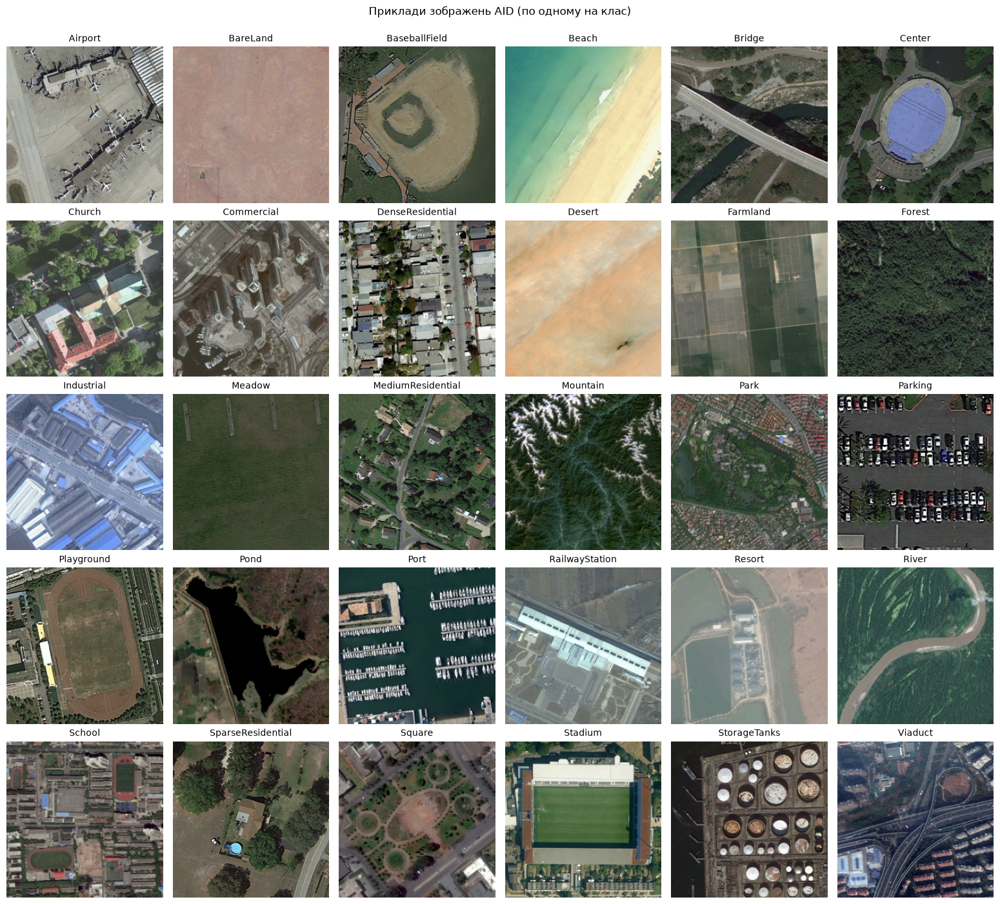

In [10]:
# По одному випадковому зображенню з кожного класу
n_cols = 6
n_rows = int(np.ceil(NUM_CLASSES / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(2.6 * n_cols, 2.8 * n_rows))
for ax in axes.flat:
    ax.axis('off')
for ax, c in zip(axes.flat, classes):
    path = df[df['class'] == c].sample(1, random_state=SEED).path.iloc[0]
    with Image.open(DATA_DIR / path) as im:
        ax.imshow(im.convert('RGB').resize((224, 224)))
    ax.set_title(c, fontsize=10)
plt.suptitle('Приклади зображень AID (по одному на клас)', y=1.0)
plt.tight_layout()
plt.show()

### Візуально схожі класи

Деякі класи відрізняються лише щільністю забудови чи контекстом — саме між ними очікуємо найбільше помилок класифікації.
Нижче — по 4 приклади для кількох таких груп (назви класів підбираються автоматично, якщо вони є в датасеті).

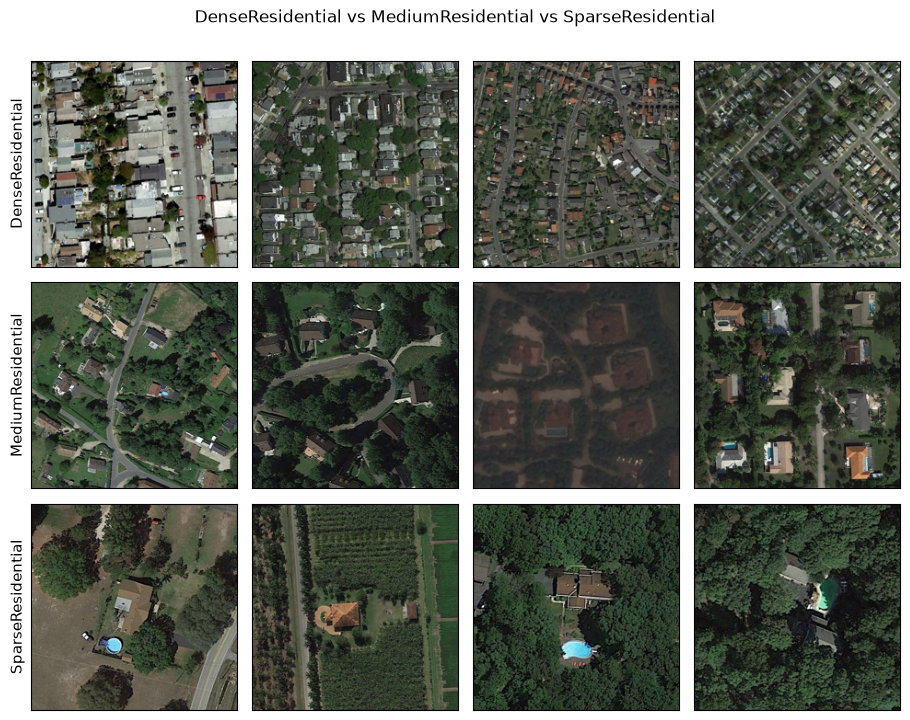

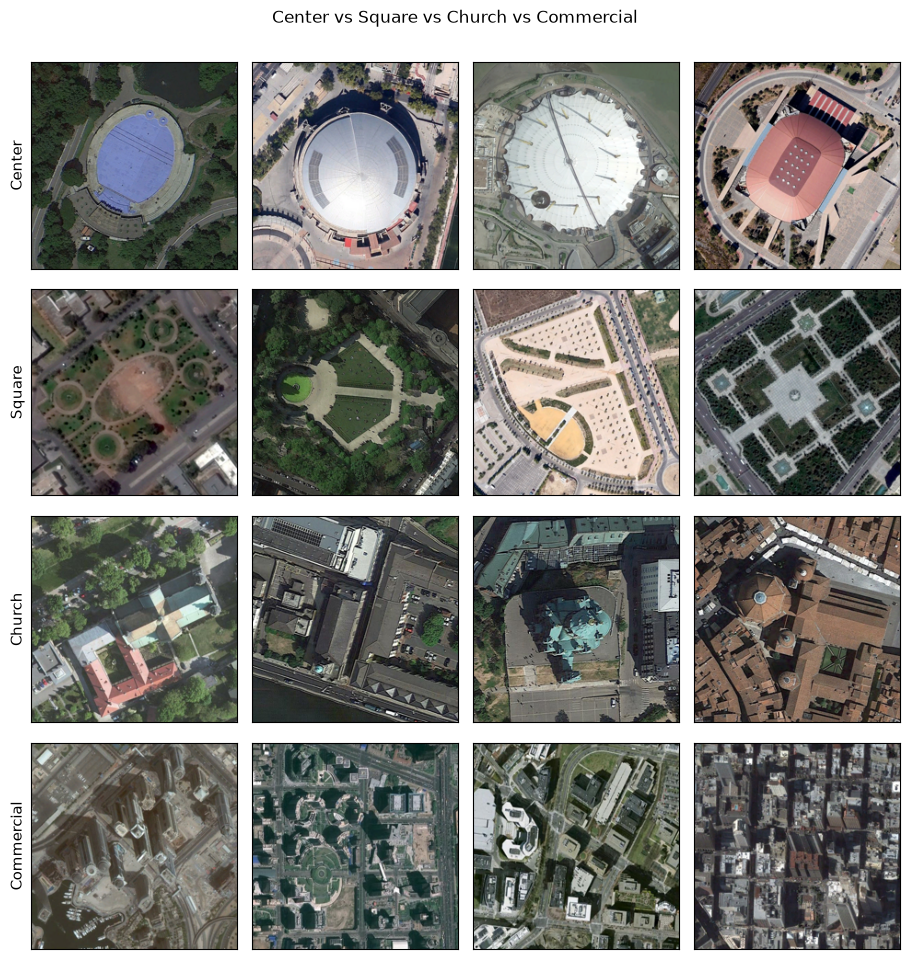

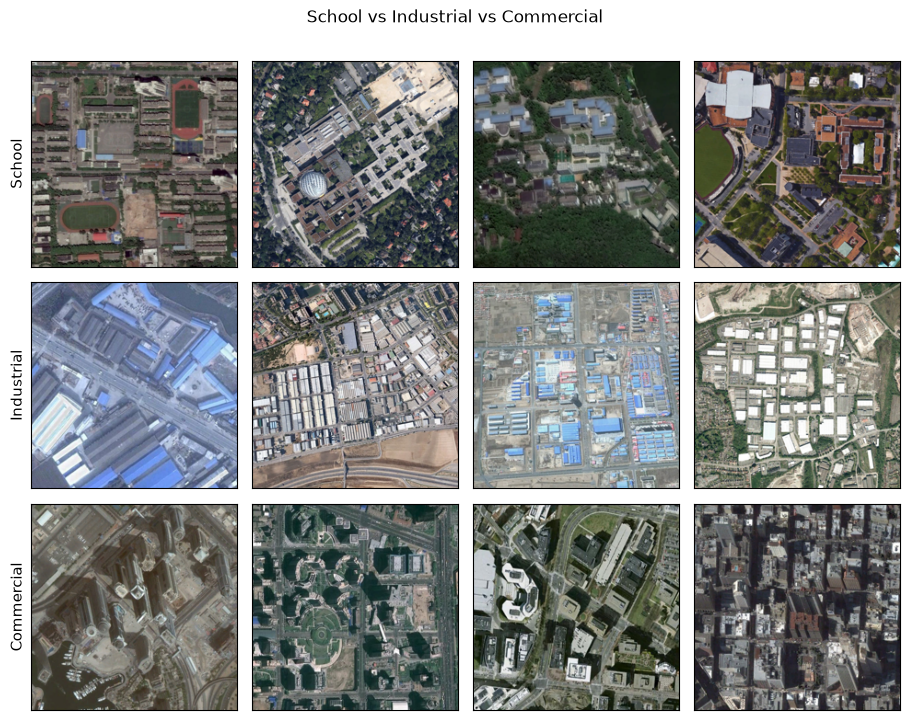

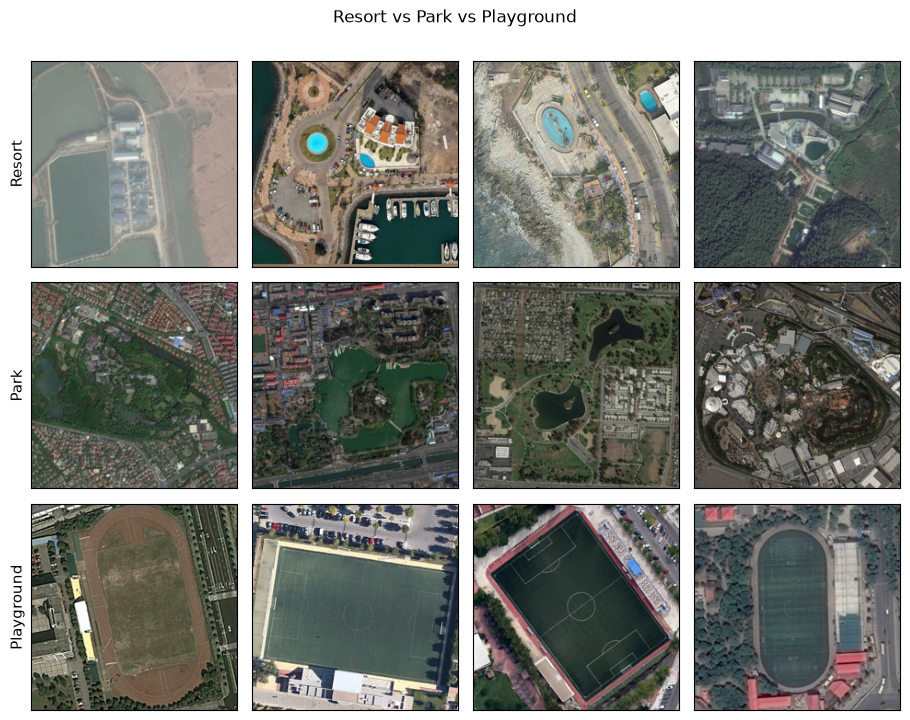

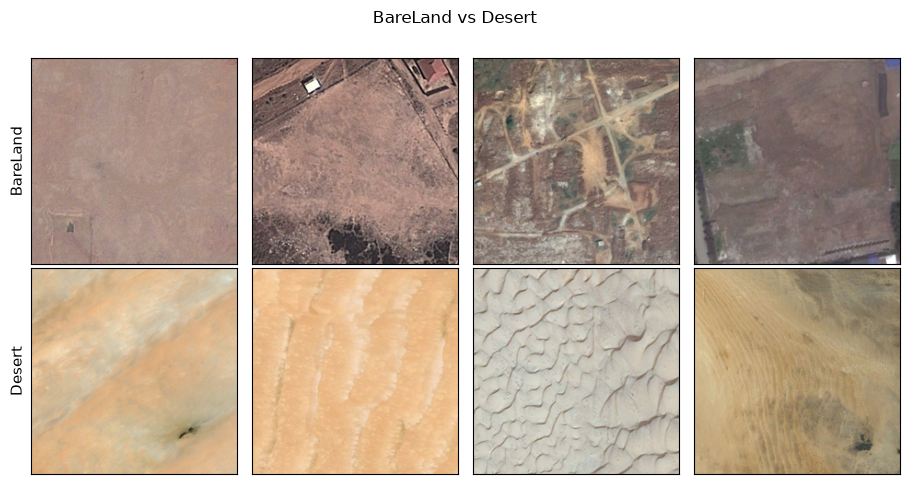

In [11]:
SIMILAR_GROUPS = [
    ['DenseResidential', 'MediumResidential', 'SparseResidential'],
    ['Center', 'Square', 'Church', 'Commercial'],
    ['School', 'Industrial', 'Commercial'],
    ['Resort', 'Park', 'Playground'],
    ['BareLand', 'Desert'],
]
norm = lambda s: s.lower().replace('_', '').replace(' ', '')
by_norm = {norm(c): c for c in classes}
groups = [[by_norm[norm(c)] for c in g if norm(c) in by_norm] for g in SIMILAR_GROUPS]
groups = [g for g in groups if len(g) >= 2]

N_PER_CLASS = 4
for g in groups:
    fig, axes = plt.subplots(len(g), N_PER_CLASS, figsize=(2.3 * N_PER_CLASS, 2.4 * len(g)))
    for row, c in zip(axes, g):
        paths = df[df['class'] == c].sample(N_PER_CLASS, random_state=SEED).path
        for ax, p in zip(row, paths):
            with Image.open(DATA_DIR / p) as im:
                ax.imshow(im.convert('RGB').resize((224, 224)))
            ax.set_xticks([]); ax.set_yticks([])
        row[0].set_ylabel(c, fontsize=11)
    plt.suptitle(' vs '.join(g), y=1.0)
    plt.tight_layout()
    plt.show()

## 5. Колірна статистика

На підвибірці (по 40 зображень з класу, зменшених до 64×64) рахуємо:
* середнє та стандартне відхилення каналів RGB по датасету — порівнюємо з нормалізацією ImageNet;
* середній колір кожного класу — показує, наскільки клас можна відрізнити вже лише за кольором.

In [12]:
N_COLOR = 40
sample = df.groupby('class').sample(N_COLOR, random_state=SEED)   # у кожному класі ≥ 220 зображень

pixels = {}
for c, p in tqdm(zip(sample['class'], sample['path']), total=len(sample), desc='Колірна статистика'):
    with Image.open(DATA_DIR / p) as im:
        arr = np.asarray(im.convert('RGB').resize((64, 64)), dtype=np.float32) / 255
    pixels.setdefault(c, []).append(arr.reshape(-1, 3))
pixels = {c: np.concatenate(v) for c, v in pixels.items()}
all_px = np.concatenate(list(pixels.values()))

IMAGENET_MEAN, IMAGENET_STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]
pd.DataFrame({'AID mean': all_px.mean(0), 'AID std': all_px.std(0),
              'ImageNet mean': IMAGENET_MEAN, 'ImageNet std': IMAGENET_STD},
             index=['R', 'G', 'B']).round(3)

Колірна статистика: 100%|██████████| 1200/1200 [00:07<00:00, 165.72it/s]


,AID mean,AID std,ImageNet mean,ImageNet std
R,0.397,0.199,0.485,0.229
G,0.407,0.175,0.456,0.224
B,0.366,0.173,0.406,0.225


/tmp/ipykernel_24045/2551163426.py:2: Pandas4Warning: Starting with pandas version 4.0 all arguments of mean will be keyword-only.
  class_mean['brightness'] = class_mean[['R', 'G', 'B']].mean(1)


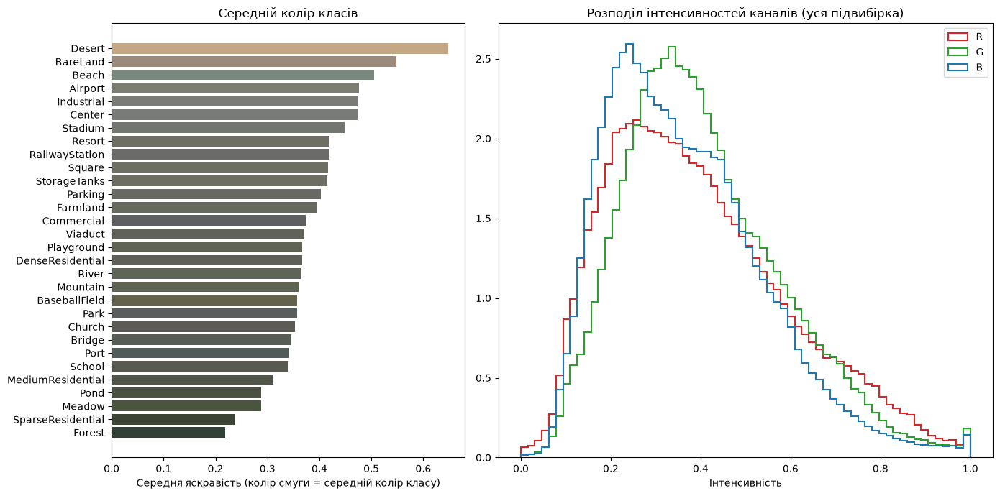

In [13]:
class_mean = pd.DataFrame({c: v.mean(0) for c, v in pixels.items()}, index=['R', 'G', 'B']).T
class_mean['brightness'] = class_mean[['R', 'G', 'B']].mean(1)
class_mean = class_mean.sort_values('brightness')

fig, axes = plt.subplots(1, 2, figsize=(14, 7), gridspec_kw={'width_ratios': [1, 1.4]})
axes[0].barh(class_mean.index, class_mean['brightness'], color=class_mean[['R', 'G', 'B']].values)
axes[0].set_xlabel('Середня яскравість (колір смуги = середній колір класу)')
axes[0].set_title('Середній колір класів')

for ch, color in zip(range(3), ['tab:red', 'tab:green', 'tab:blue']):
    axes[1].hist(all_px[:, ch], bins=64, histtype='step', color=color, lw=1.5, label='RGB'[ch], density=True)
axes[1].set_title('Розподіл інтенсивностей каналів (уся підвибірка)')
axes[1].set_xlabel('Інтенсивність'); axes[1].legend()
plt.tight_layout()
plt.show()

**Висновок** _(перевірити після запуску)_: зображення AID темніші (mean ≈ 0.37–0.41 проти 0.41–0.49) і менш контрастні
(std ≈ 0.17–0.20 проти ≈ 0.22), ніж ImageNet. Для попередньо навчених моделей все одно використовуємо нормалізацію
ImageNet — саме на ній навчалися їхні ваги; для учня, що навчається з нуля, можна взяти власні mean/std AID. Середні кольори багатьох класів
схожі (сірі міські сцени, зелені природні), тож колір сам по собі класи не розділяє — моделі потрібні текстурні й
просторові ознаки.

## 6. Поділ на train / val / test (70 / 15 / 15)

Стратифікований поділ із фіксованим `SEED`. Код збігається з основним ноутбуком, тому `split.csv` ідентичний.
* **train** — навчання (аугментація — лише тут);
* **val** — вибір моделей, епох, гіперпараметрів (T, α для дистиляції тощо);
* **test** — лише фінальна оцінка.

In [ ]:
base = df[['path', 'class', 'label']]
train_df, tmp_df = train_test_split(base, test_size=0.30, stratify=base['label'], random_state=SEED)
val_df, test_df = train_test_split(tmp_df, test_size=0.50, stratify=tmp_df['label'], random_state=SEED)
split_df = pd.concat([train_df.assign(split='train'), val_df.assign(split='val'), test_df.assign(split='test')])
split_df = split_df.reset_index(drop=True)

split_file = OUT_DIR / 'split.csv'
split_df.to_csv(split_file, index=False)
print('Поділ збережено в', split_file.resolve())
print(split_df['split'].value_counts().reindex(['train', 'val', 'test']).to_dict())

In [ ]:
# Перевірка стратифікації: кількість по класах у кожній вибірці та максимальне відхилення часток
ct = pd.crosstab(split_df['class'], split_df['split'])[['train', 'val', 'test']]
shares = ct / ct.sum()
print(f'Максимальна різниця частки класу між вибірками: {(shares.max(1) - shares.min(1)).max() * 100:.2f} п.п.')

ax = ct.loc[counts.index].plot.barh(stacked=True, figsize=(9, 9), color=['steelblue', 'orange', 'seagreen'])
ax.set_xlabel('Кількість зображень'); ax.set_title('Розподіл класів у train / val / test')
plt.tight_layout()
plt.show()
ct.T

In [ ]:
# Дублікати не повинні опинитися в різних вибірках
if len(dup):
    leak = split_df.merge(df[['path', 'md5']], on='path').groupby('md5')['split'].nunique().gt(1).sum()
    print(f'Груп дублікатів, розкиданих по різних вибірках: {leak}')
else:
    print('Дублікатів немає — витоку між вибірками через однакові файли немає.')

## 7. Підсумок етапу 2

_(заповнити після запуску)_
* **30 класів**, **~10 000** зображень 600×600 RGB; розподіл помірно незбалансований (max/min ≈ 1.9) → метрики accuracy + macro-F1.
* Є візуально схожі групи класів (житлова забудова різної щільності, центр/площа/комерційна зона, курорт/парк) — очікуємо, що
  саме вони дадуть більшість помилок у матрицях невідповідностей (завдання 8).
* Зображення темніші й менш контрастні, ніж ImageNet; для pretrained-моделей — нормалізація ImageNet.
* Поділ 70/15/15, стратифікований, `SEED=42` → `artifacts/split.csv`. Щоб основний ноутбук використав саме його,
  покладіть файл у `CKPT_DIR` (там він підхоплюється автоматично) або завантажте його на Kaggle разом із ноутбуком.